# 05 — Multi-City Comparative Analysis

Notebooks 01–04 built and validated the pipeline on one house (Karachi House 38). Here the same pipeline is packaged into **reusable functions** and run on **18 houses in 6 Pakistani cities** (Karachi, Lahore, Peshawar, Multan, Skardu, Islamabad).

For each house we report, on its own test period:
- **nMAE (day-ahead)** = day-ahead MAE ÷ the house's mean usage. Raw MAE in kW is not comparable between a big house and a small one.
- **Skill vs persistence (1 h)** and **skill vs seasonal naive (day-ahead)**: `1 - MAE_model / MAE_baseline`. `0` = no better than the baseline, `< 0` = worse.
- **Anomaly rate** at `K = 5` (threshold calibrated on validation, see notebook 04).
- **% observed**: share of hours that are real measurements. Houses with low coverage deserve less trust.

## 5.1 Imports and paths

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

DATA_ROOT = "/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset"
WEATHER_ROOT = "/kaggle/input/weather-dataset/weather_dataset"
WORK_DIR = "."  

HOUSES = {
    "Karachi":   [38, 39, 40],
    "Lahore":    [7, 8, 9],
    "Peshawar":  [26, 29, 30],
    "Multan":    [18, 19, 20],
    "Skardu":    [56, 57, 59],
    "Islamabad": [48, 49, 50],
}

def house_path(city, n):
    return f"{DATA_ROOT}/{city}/{city.lower()}_House{n}.csv"

## 5.2 Reusable pipeline functions

Everything from notebooks 01 and 02 as small functions, each doing one job:

- `clean_house` — repair timestamps, remove sensor downtime, hourly table with the `observed` flag.
- `add_features` — calendar, lag and rolling features (past hours only).
- `split_rows` — real hours only, 70 / 10 / 20 chronological split.
- `fit_delta` / `predict_delta` — Random Forest on the change from a base lag.
- `anomaly_z` — validation-calibrated anomaly score.

In [2]:
LAGS = [1, 2, 24, 48, 168]
BASE_FEATURES = (["hour", "dow", "is_weekend"] + [f"lag_{l}" for l in LAGS]
                 + ["roll_mean_24", "roll_std_24", "roll_mean_168"])
DAY_AHEAD = ["hour", "dow", "is_weekend", "lag_24", "lag_48", "lag_168"]


def clean_house(filepath):
    # Load one house, repair timestamps, remove sensor downtime, return an HOURLY table.
    df = pd.read_csv(filepath)
    if "Usage..kW." in df.columns:                      # one file uses a different column name
        df = df.rename(columns={"Usage..kW.": "Usage (kW)"})

    # 1) repeated timestamps -> re-stamp one second apart
    times = pd.to_datetime(df["datetime"], format="mixed")
    run_id = (times != times.shift()).cumsum()
    position_in_run = df.groupby(run_id).cumcount()
    df["datetime"] = times + pd.to_timedelta(position_in_run, unit="s")
    df = df.set_index("datetime").sort_index()
    df = df[~df.index.duplicated(keep="first")]
    df = df.apply(pd.to_numeric, errors="coerce")

    # 2) 10+ zero minutes in a row = sensor downtime -> missing
    is_zero = df["Usage (kW)"] == 0
    zero_run = (is_zero != is_zero.shift()).cumsum()
    run_len = is_zero.groupby(zero_run).transform("size")
    df.loc[is_zero & (run_len >= 10), :] = np.nan

    # 3) hourly mean; hours with less than half an hour of data are missing
    usage_cols = [c for c in ["Usage (kW)", "Washing Machine (kW)", "BR_1_AC (kW)", "BR_2_AC (kW)",
                              "Fridge + Water Pump (kW)", "Kitchen (kW)"] if c in df.columns]
    hourly = df[usage_cols].resample("h").mean()
    n_rows = df["Usage (kW)"].resample("h").count()
    hourly.loc[n_rows < 30, :] = np.nan

    # 4) remember which hours are real, then fill only short gaps (max 3 hours)
    hourly["observed"] = hourly["Usage (kW)"].notna()
    hourly[usage_cols] = hourly[usage_cols].interpolate(method="time", limit=3, limit_area="inside")
    return hourly


def add_features(hourly):
    # Calendar + lag + rolling features. Rolling features use ONLY past hours (shift(1)).
    d = hourly.copy()
    s = d["Usage (kW)"]
    d["hour"] = d.index.hour
    d["dow"] = d.index.dayofweek
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    for lag in LAGS:
        d[f"lag_{lag}"] = s.shift(lag)
    past = s.shift(1)
    d["roll_mean_24"] = past.rolling(24).mean()
    d["roll_std_24"] = past.rolling(24).std()
    d["roll_mean_168"] = past.rolling(168).mean()
    d["y"] = s
    return d


def split_rows(d, features):
    # Keep only real (observed) hours with complete features, then split 70 / 10 / 20 in time order.
    d = d.dropna(subset=features + ["y"])
    d = d[d["observed"]]
    n = len(d)
    a, b = int(0.7 * n), int(0.8 * n)
    return d.iloc[:a], d.iloc[a:b], d.iloc[b:]


def smape(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return 100 * np.mean(2 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8))


def make_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                 n_jobs=-1, random_state=42)


def fit_delta(train, features, base):
    # Random Forest that learns the CHANGE from a base lag (y - base), not the raw level.
    model = make_rf()
    model.fit(train[features], train["y"] - train[base])
    return model


def predict_delta(model, df, features, base):
    return df[base].values + model.predict(df[features])


def anomaly_z(model, features, val, test):
    # Relative residual + robust z-score. Calibrated on VALIDATION, applied to TEST.
    pred_val = model.predict(val[features])
    eps = 0.1 * val["y"].mean()
    rel_val = (val["y"].values - pred_val) / (pred_val + eps)
    median = np.median(rel_val)
    sigma = 1.4826 * np.median(np.abs(rel_val - median))
    pred_test = model.predict(test[features])
    rel_test = (test["y"].values - pred_test) / (pred_test + eps)
    return pred_test, (rel_test - median) / sigma

## 5.3 Evaluate one house

For one house we train three Random Forests: a **1-hour delta** model, a **day-ahead delta** model, and a **plain** model for anomaly detection.

In [3]:
def evaluate_house(filepath, k=5):
    hourly = clean_house(filepath)
    d = add_features(hourly)
    train, val, test = split_rows(d, BASE_FEATURES)
    y = test["y"]

    # 1 hour ahead vs persistence
    rf_1h = fit_delta(train, BASE_FEATURES, "lag_1")
    mae_persist = mean_absolute_error(y, test["lag_1"])
    mae_rf_1h = mean_absolute_error(y, predict_delta(rf_1h, test, BASE_FEATURES, "lag_1"))

    # day ahead vs seasonal naive (same hour yesterday)
    rf_24 = fit_delta(train, DAY_AHEAD, "lag_24")
    mae_naive24 = mean_absolute_error(y, test["lag_24"])
    mae_rf_24 = mean_absolute_error(y, predict_delta(rf_24, test, DAY_AHEAD, "lag_24"))

    # anomalies (plain RF, relative residual, calibrated on validation)
    rf_plain = make_rf().fit(train[BASE_FEATURES], train["y"])
    pred, z = anomaly_z(rf_plain, BASE_FEATURES, val, test)

    return {"test_hours": len(test),
            "pct_observed": 100 * hourly["observed"].mean(),
            "nmae_24h": mae_rf_24 / y.mean(),
            "skill_1h": 1 - mae_rf_1h / mae_persist,
            "skill_24h": 1 - mae_rf_24 / mae_naive24,
            "anomaly_pct": 100 * (np.abs(z) > k).mean()}


# quick test on one house
evaluate_house(house_path("Karachi", 38))

{'test_hours': 1645,
 'pct_observed': np.float64(99.98808530918623),
 'nmae_24h': np.float64(0.43037002478753034),
 'skill_1h': -0.07440709344891694,
 'skill_24h': 0.0438867224656212,
 'anomaly_pct': np.float64(0.182370820668693)}

## 5.4 Run all 18 houses (about 10–15 minutes)

In [4]:
records = []
failures = {}

for city in HOUSES:
    for n in HOUSES[city]:
        name = f"{city}_{n}"
        try:
            row = evaluate_house(house_path(city, n))
            row["house"] = name
            row["city"] = city
            records.append(row)
            print("done:", name)
        except Exception as e:
            failures[name] = f"{type(e).__name__}: {e}"

summary = pd.DataFrame(records)
summary = summary[["house", "city", "test_hours", "pct_observed", "nmae_24h", "skill_1h", "skill_24h", "anomaly_pct"]]

if failures:
    print("FAILED houses:", failures)
summary.sort_values("skill_24h", ascending=False).round(3).reset_index(drop=True)

done: Karachi_38
done: Karachi_39
done: Karachi_40
done: Lahore_7
done: Lahore_8
done: Lahore_9
done: Peshawar_26
done: Peshawar_29
done: Peshawar_30
done: Multan_18
done: Multan_19
done: Multan_20
done: Skardu_56
done: Skardu_57
done: Skardu_59
done: Islamabad_48
done: Islamabad_49
done: Islamabad_50


,house,city,test_hours,pct_observed,nmae_24h,skill_1h,skill_24h,anomaly_pct
0,Lahore_9,Lahore,1660,98.550,0.469,0.063,0.160,0.422
1,Islamabad_50,Islamabad,1286,87.422,0.468,0.176,0.155,0.855
2,Karachi_39,Karachi,1668,99.693,0.474,0.092,0.150,1.019
3,Multan_20,Multan,1681,99.737,0.357,0.034,0.126,2.974
4,Skardu_59,Skardu,1287,90.292,0.733,-0.221,0.104,1.632
5,Lahore_8,Lahore,1647,97.808,0.263,0.073,0.092,1.032
6,Multan_18,Multan,1719,99.989,0.271,0.108,0.070,1.745
7,Multan_19,Multan,1414,89.155,0.371,0.052,0.060,0.990
8,Lahore_7,Lahore,257,71.004,0.422,-0.006,0.056,0.389
9,Skardu_56,Skardu,1056,76.450,0.686,0.089,0.056,5.019


## 5.5 City-wise comparison

,nmae_24h,skill_1h,skill_24h,anomaly_pct,pct_observed
city,,,,,
Multan,0.333,0.064,0.085,1.903,96.294
Lahore,0.385,0.043,0.103,0.614,89.121
Karachi,0.427,0.010,0.066,0.951,99.642
Islamabad,0.481,0.041,0.034,1.279,94.312
Peshawar,0.502,0.091,-0.038,1.279,88.843
Skardu,0.891,-0.135,0.056,2.903,87.027


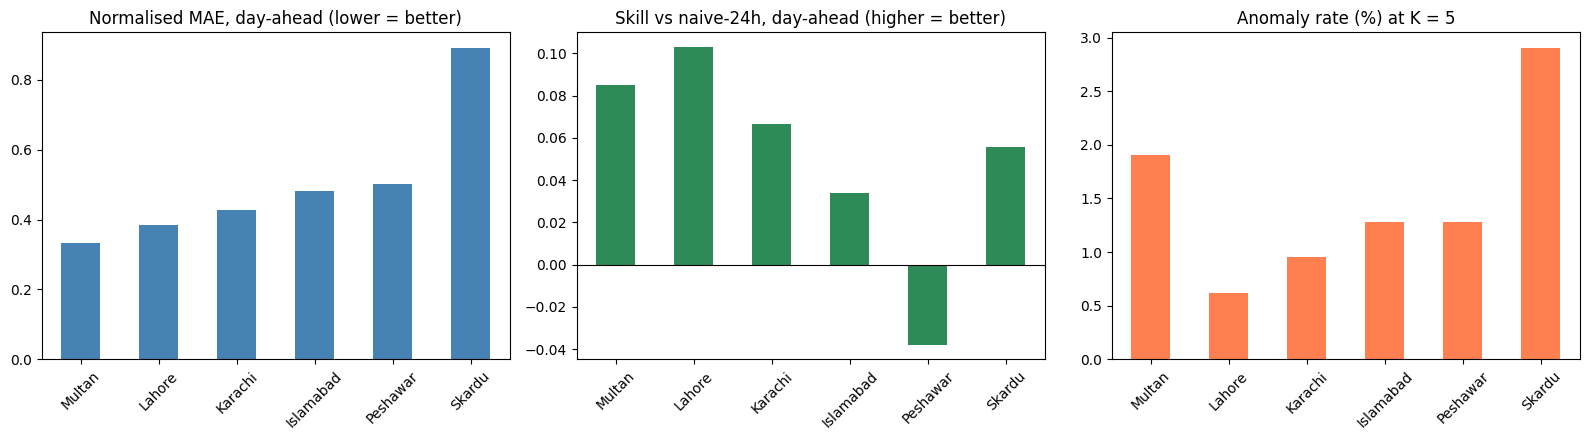

In [5]:
city_avg = summary.groupby("city")[["nmae_24h", "skill_1h", "skill_24h", "anomaly_pct", "pct_observed"]].mean()
city_avg = city_avg.sort_values("nmae_24h")
display(city_avg.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
city_avg["nmae_24h"].plot(kind="bar", ax=axes[0], color="steelblue", title="Normalised MAE, day-ahead (lower = better)")
city_avg["skill_24h"].plot(kind="bar", ax=axes[1], color="seagreen", title="Skill vs naive-24h, day-ahead (higher = better)")
city_avg["anomaly_pct"].plot(kind="bar", ax=axes[2], color="coral", title="Anomaly rate (%) at K = 5")
axes[1].axhline(0, color="k", linewidth=0.8)
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

summary.to_csv(f"{WORK_DIR}/multi_city_summary.csv", index=False)

In [6]:
n_houses = len(summary)
print("Houses where RF beats seasonal naive (day-ahead):", int((summary["skill_24h"] > 0).sum()), "/", n_houses)
print("Houses where RF beats persistence (1 hour)      :", int((summary["skill_1h"] > 0).sum()), "/", n_houses)
print("Lowest nMAE city :", city_avg["nmae_24h"].idxmin(), round(city_avg["nmae_24h"].min(), 3))
print("Highest nMAE city:", city_avg["nmae_24h"].idxmax(), round(city_avg["nmae_24h"].max(), 3))
print("Best day-ahead skill city :", city_avg["skill_24h"].idxmax(), round(city_avg["skill_24h"].max(), 3))
print("Worst day-ahead skill city:", city_avg["skill_24h"].idxmin(), round(city_avg["skill_24h"].min(), 3))
print("Highest anomaly-rate city :", city_avg["anomaly_pct"].idxmax(), round(city_avg["anomaly_pct"].max(), 2), "%")

Houses where RF beats seasonal naive (day-ahead): 14 / 18
Houses where RF beats persistence (1 hour)      : 12 / 18
Lowest nMAE city : Multan 0.333
Highest nMAE city: Skardu 0.891
Best day-ahead skill city : Lahore 0.103
Worst day-ahead skill city: Peshawar -0.038
Highest anomaly-rate city : Skardu 2.9 %


### Key findings (read together with the printed numbers above)

- **Gains over the baselines are modest.** The model helps most at day-ahead; at 1 hour ahead persistence is hard to beat in many houses.
- **Cities differ.** Some cities are clearly easier to forecast (lower nMAE) than others. Cities with very spiky usage (e.g. Skardu) have a high nMAE and a higher anomaly rate: the detector alarms more because the load itself is less predictable.
- **Anomaly rate is not an accuracy score.** With a validation-calibrated threshold it depends on how spiky and how stable a house is; a low rate does not prove the detector is "good" and a high rate does not prove it is "bad".
- **Trust depends on data coverage and test length.** Houses with a low `pct_observed` or few test hours have less reliable numbers. One house can behave very differently from the rest of its city (an outlier house).
- **Test windows are short and seasonal.** Every house is tested on roughly the last 20% of about one year of data, which for most houses is the summer vacation period; results may not transfer to other seasons.

**Next notebook:** `06_model_export_for_deployment.ipynb`